# COU 07506 Digital Signal Processing
## Week 1: Setting Up the DSP Laboratory

**Name:** RAHMA ABDALLAH VUMBI

**Registration Number:** 250242499374

**Class:** BENG24COE-3



# Pre-lab preparation

1. Smartphone:
   Processes audio signals during voice calls.

2. Television:
   Processes audio and video signals.

3. Digital camera:
   Processes image signals.

# TASK 1.1 — MY FIRST NOTEBOOK

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

In [2]:
n = np.arange(-5, 11)

print(n)

[-5 -4 -3 -2 -1  0  1  2  3  4  5  6  7  8  9 10]


In [3]:
delta = (n == 0).astype(float)

print(delta)

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [5]:
step = (n >= 0).astype(float)

print(step)

[0. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
ramp = n * step

print(ramp)

[-0. -0. -0. -0. -0.  0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]


In [7]:
expo = 0.8**n * step

print(expo)

[0.         0.         0.         0.         0.         1.
 0.8        0.64       0.512      0.4096     0.32768    0.262144
 0.2097152  0.16777216 0.13421773 0.10737418]


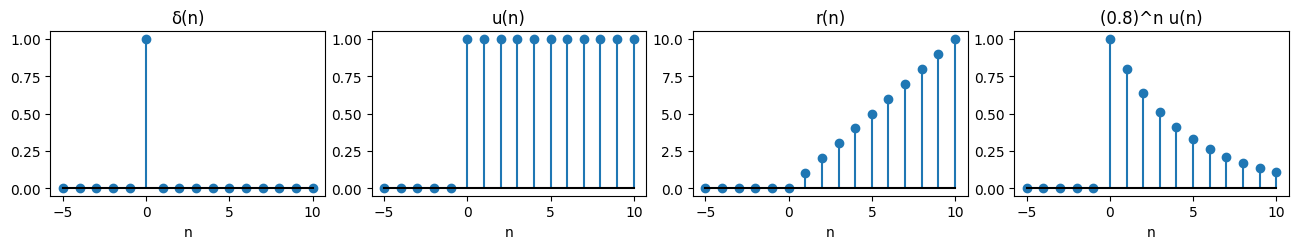

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()


## Task 1.2 — Changing the Parameters

### Part A: Exponential Signals


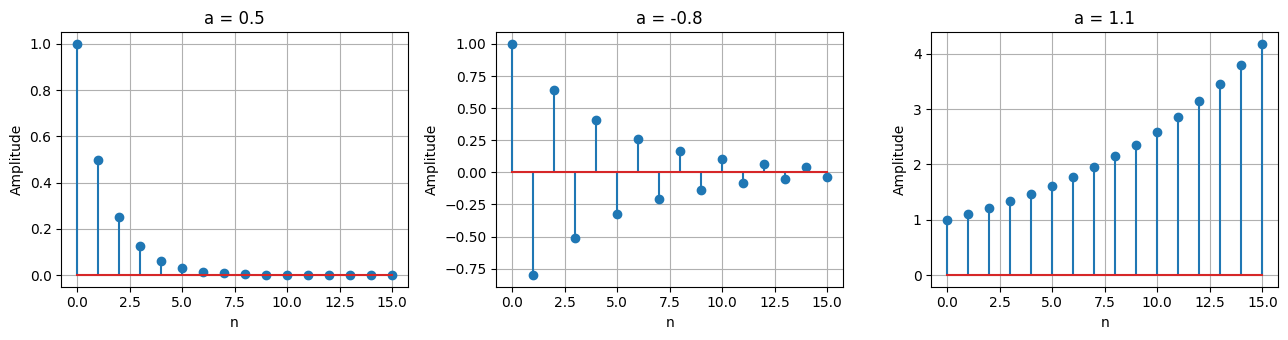

In [9]:

n = np.arange(0, 16)

a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, a in zip(axes, a_values):
    x = a**n
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()



### Part B: Cosine Signals
Plot cos(2πn/8) and cos(2πn/7.5) for 0 ≤ n ≤ 40.


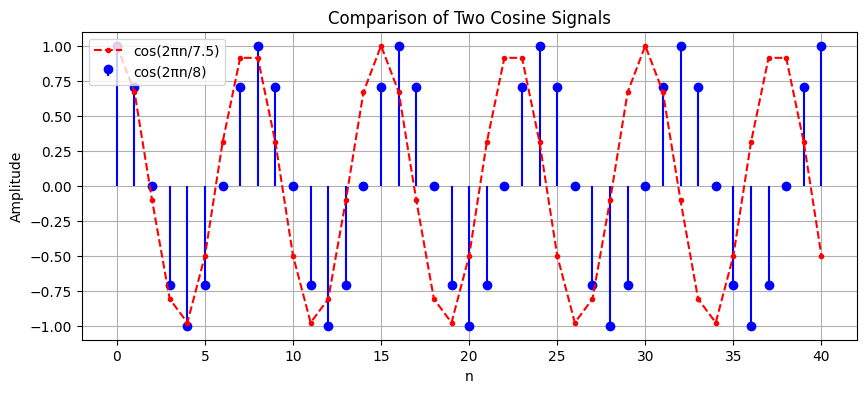

In [10]:

n = np.arange(0, 41)

x1 = np.cos(2*np.pi*n/8)
x2 = np.cos(2*np.pi*n/7.5)

plt.figure(figsize=(10, 4))

plt.stem(n, x1, linefmt="b-", markerfmt="bo",
         basefmt=" ", label="cos(2πn/8)")

plt.plot(n, x2, "r--o",
         label="cos(2πn/7.5)", markersize=3)

plt.xlabel("n")
plt.ylabel("Amplitude")
plt.title("Comparison of Two Cosine Signals")
plt.legend()
plt.grid(True)
plt.show()


ANSWER

*   cos(2πn/8) repeats exactly because its period is 8 samples, which is an integer.

*   cos(2πn/8) repeats exactly because its period is 8 samples, which is an integer.



### Task 1.3 — Working with Audio

 1. Reading the audio

In [12]:

import os

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x.astype(float)
    x = x / np.max(np.abs(x))

else:
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)

t = np.arange(len(x)) / fs

print("Sampling frequency:", fs, "Hz")
print("Duration:", len(x)/fs, "seconds")
print("Number of samples:", len(x))


Sampling frequency: 16000 Hz
Duration: 2.0 seconds
Number of samples: 32000


2. ploting the audio waveform

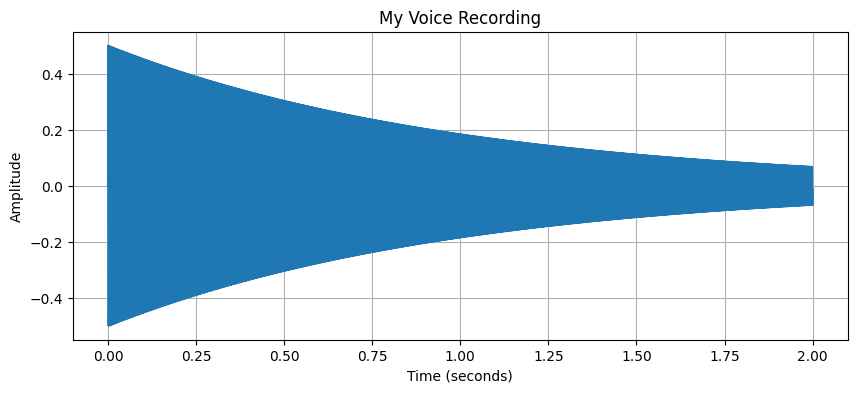

In [13]:

plt.figure(figsize=(10, 4))

plt.plot(t, x)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)

plt.show()


3. playing the audio

In [14]:

from IPython.display import Audio, display

display(Audio(x, rate=fs))



## Analysis Questions

### Question 1
What is the sampling rate of your phone's recording? How many numbers are needed to store one minute of it in mono?

**Answer:** The sampling rate is the value of fs printed by the Python program. The number of samples needed for one minute is:

Number of samples = Sampling rate × 60.

### Question 2
Why is a stem plot more appropriate than a continuous line for x(n)?

**Answer:** A stem plot is more appropriate because a discrete-time signal is defined only at integer sample positions. It shows individual samples clearly without suggesting that values exist continuously between samples.

### Question 3
For a = 1.1 the exponential grows. Which property of a system would such a signal violate if it were an impulse response?

**Answer:** It would violate BIBO stability because the impulse response grows and is not absolutely summable.



## AI-use Statement

AI tools used: ChatGPT.

Used for: Explaining DSP concepts, understanding Python code and debugging.

How I verified the output: I ran the notebook cells in Google Colab and checked the generated plots and audio output.


